# K-Means

K-Means is **unsupervised**: it groups flows into `k` clusters without using labels. This notebook uses it in two ways:

1. **Anomaly detector (like the autoencoder).** Cluster **normal flows only**. A new flow's anomaly score is its distance to the nearest cluster centre. Normal flows sit near a centre, and flows unlike normal traffic sit far from all of them. Experimental, and expect it to score below the supervised models.
2. **Cluster-majority classifier.** Cluster all training flows, give each cluster the most common label in it, and classify a new flow by the cluster it lands in. A simple, fast way to compare against the supervised models.

**Feasibility:** easy and fast, and cheap to run live (one distance calculation per cluster). It does not know about attack types, so the multiclass result will be weak.

## 1. Imports

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

K_GRID = (4, 8, 16, 32)     # candidate numbers of clusters for the anomaly detector
K = 16                      # clusters actually used for the anomaly detector
PERCENTILE = 95             # flag the worst 5% of normal flows (about 5% false alarms)
CLUSTER_K = 60              # clusters for the cluster-majority classifier (more clusters = finer)

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Helpers (same evaluation as every other notebook)

In [4]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

## 5. Anomaly detector: choose k

The elbow table shows how tightly the normal flows cluster for each k (lower inertia means tighter). The silhouette score is computed on a sample, and higher is better.

,k,inertia,silhouette (sample)
0,4,226134.812,0.291
1,8,137057.719,0.361
2,16,70117.109,0.455
3,32,37827.789,0.440


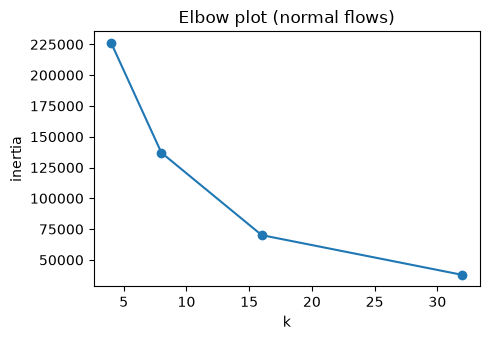

In [5]:
X_train_normal = X_train[yb_train == 0]
X_val_normal = X_val[yb_val == 0]
sample = X_train_normal[np.random.default_rng(SEED).choice(len(X_train_normal), size=min(5000, len(X_train_normal)), replace=False)]

rows = []
for k in K_GRID:
    km = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(X_train_normal)
    sil = silhouette_score(sample, km.predict(sample)) if k > 1 else np.nan
    rows.append({"k": k, "inertia": km.inertia_, "silhouette (sample)": sil})
elbow = pd.DataFrame(rows)
display(elbow.round(3))

plt.figure(figsize=(5, 3.5))
plt.plot(elbow["k"], elbow["inertia"], marker="o")
plt.xlabel("k"); plt.ylabel("inertia"); plt.title("Elbow plot (normal flows)")
plt.tight_layout(); plt.show()

## 6. Anomaly detector: train on normal flows and score

trained in 0.4s
threshold: 2.0854   ROC-AUC (threshold-free): 0.8861


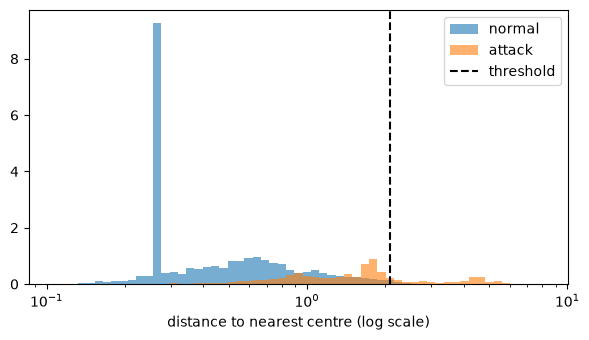

              precision    recall  f1-score   support

      Normal     0.4443    0.9499    0.6054     11200
      Attack     0.9496    0.4424    0.6036     23869

    accuracy                         0.6045     35069
   macro avg     0.6969    0.6962    0.6045     35069
weighted avg     0.7882    0.6045    0.6042     35069

ROC-AUC:              0.8861
False positive rate:  0.0501  (561 normal flows flagged as attacks)
False negative rate:  0.5576  (13309 attacks missed)


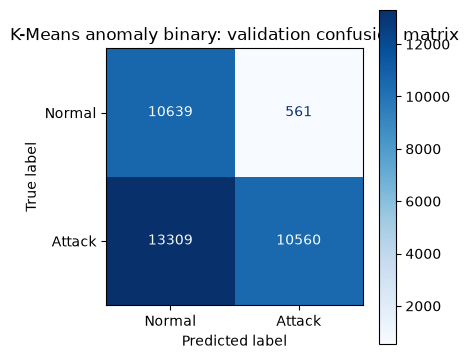

In [6]:
t0 = time.time()
km_anom = KMeans(n_clusters=K, n_init=5, random_state=SEED).fit(X_train_normal)
print(f"trained in {time.time() - t0:.1f}s")


def anomaly_score(X):
    return km_anom.transform(X).min(axis=1)       # distance to the nearest cluster centre


score_val = anomaly_score(X_val)
threshold = float(np.percentile(score_val[yb_val == 0], PERCENTILE))
pred_anom = (score_val >= threshold).astype(int)
print(f"threshold: {threshold:.4f}   ROC-AUC (threshold-free): {roc_auc_score(yb_val, score_val):.4f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.logspace(np.log10(max(score_val.min(), 1e-6)), np.log10(score_val.max()), 60)
ax.hist(score_val[yb_val == 0], bins=bins, alpha=0.6, density=True, label="normal")
ax.hist(score_val[yb_val == 1], bins=bins, alpha=0.6, density=True, label="attack")
ax.axvline(threshold, color="k", linestyle="--", label="threshold")
ax.set_xscale("log"); ax.set_xlabel("distance to nearest centre (log scale)"); ax.legend()
plt.tight_layout(); plt.show()

row_anom = report_binary(yb_val, pred_anom, "K-Means anomaly binary", score=score_val,
                         ms=ms_per_1000(anomaly_score, X_val))

In [7]:
# detection rate by attack type (Normal row = false alarm rate)
rows = []
for i, name in enumerate(class_names):
    m = ym_val == i
    rows.append({"true class": name, "flows": int(m.sum()),
                 "flagged as anomaly (%)": round(100 * (pred_anom[m] == 1).mean(), 2),
                 "median distance": round(float(np.median(score_val[m])), 4)})
display(pd.DataFrame(rows))

,true class,flows,flagged as anomaly (%),median distance
0,Normal,11200,5.01,0.7049
1,DoS,2453,20.02,1.7970
2,Reconnaissance,2099,9.58,1.4383
3,Fuzzers,3637,14.00,1.1668
4,Exploits,6678,23.30,1.8025
5,Generic,8000,95.61,4.4897
6,Other,1002,15.37,1.7480


## 7. Cluster-majority classifier

Each cluster is labelled by its most common class in the training data. The attack share in a cluster also serves as a score for ROC-AUC.

trained in 2.8s
              precision    recall  f1-score   support

      Normal     0.8858    0.8066    0.8443     11200
      Attack     0.9129    0.9512    0.9317     23869

    accuracy                         0.9050     35069
   macro avg     0.8993    0.8789    0.8880     35069
weighted avg     0.9042    0.9050    0.9038     35069

ROC-AUC:              0.9660
False positive rate:  0.1934  (2166 normal flows flagged as attacks)
False negative rate:  0.0488  (1165 attacks missed)


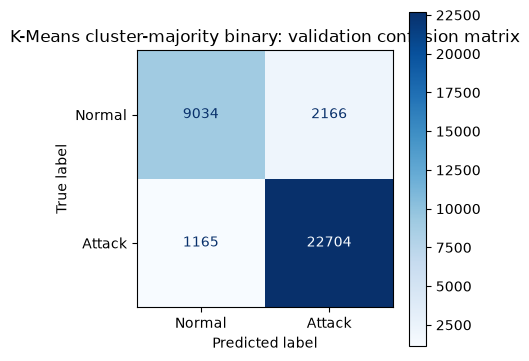

In [8]:
t0 = time.time()
km_all = KMeans(n_clusters=CLUSTER_K, n_init=3, random_state=SEED).fit(X_train)
print(f"trained in {time.time() - t0:.1f}s")

train_clusters = km_all.labels_
attack_share = np.array([yb_train[train_clusters == c].mean() if (train_clusters == c).any() else 0.0
                         for c in range(CLUSTER_K)])
major_class = np.array([np.bincount(ym_train[train_clusters == c], minlength=n_classes).argmax()
                        if (train_clusters == c).any() else 0 for c in range(CLUSTER_K)])

val_clusters = km_all.predict(X_val)
score_cm = attack_share[val_clusters]
pred_cm_bin = (score_cm >= 0.5).astype(int)
row_cm_bin = report_binary(yb_val, pred_cm_bin, "K-Means cluster-majority binary", score=score_cm,
                           ms=ms_per_1000(km_all.predict, X_val))

                precision    recall  f1-score   support

        Normal     0.8477    0.8547    0.8512     11200
           DoS     0.0000    0.0000    0.0000      2453
Reconnaissance     0.4636    0.6251    0.5324      2099
       Fuzzers     0.5284    0.4814    0.5038      3637
      Exploits     0.5006    0.7403    0.5973      6678
       Generic     0.9978    0.9673    0.9823      8000
         Other     0.0000    0.0000    0.0000      1002

      accuracy                         0.7219     35069
     macro avg     0.4769    0.5241    0.4953     35069
  weighted avg     0.6762    0.7219    0.6938     35069

macro F1:    0.4953
weighted F1: 0.6938


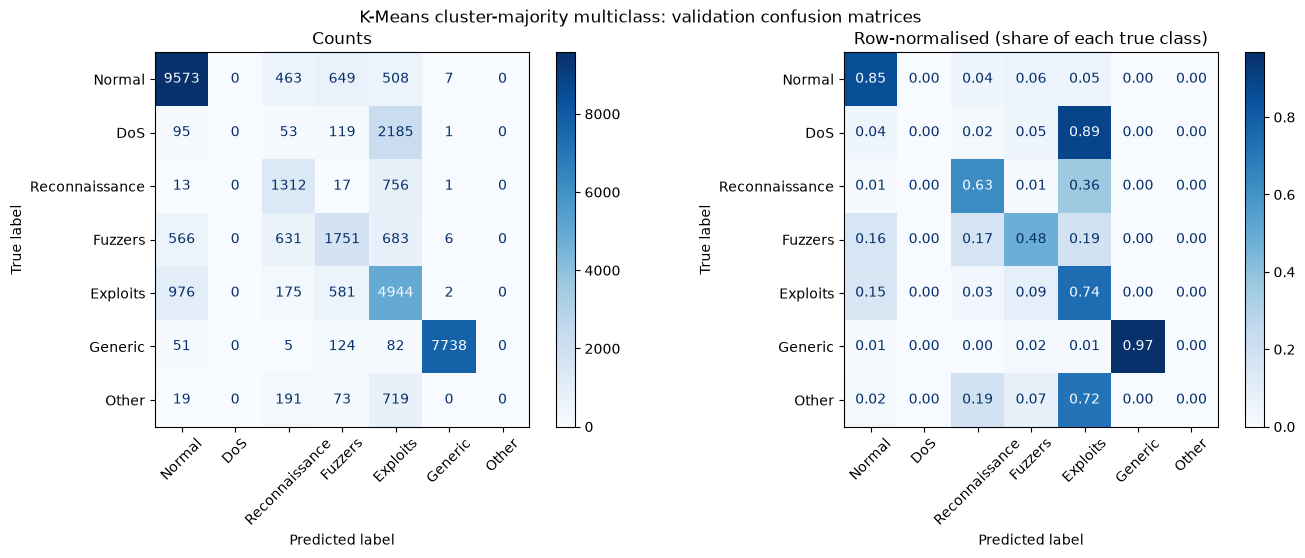

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,14.53,85.47
1,DoS,2453,96.13,0.00
2,Reconnaissance,2099,99.38,62.51
3,Fuzzers,3637,84.44,48.14
4,Exploits,6678,85.38,74.03
5,Generic,8000,99.36,96.72
6,Other,1002,98.10,0.00


In [9]:
pred_cm_multi = major_class[val_clusters]
row_cm_multi = report_multiclass(ym_val, pred_cm_multi, "K-Means cluster-majority multiclass",
                                 ms=ms_per_1000(km_all.predict, X_val))

## 8. Save and compare

The anomaly detector needs both the model and its threshold in the live pipeline.

In [10]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)
joblib.dump(km_anom, mdir / "kmeans_anomaly.joblib")
joblib.dump({"threshold": threshold, "percentile": PERCENTILE, "k": K}, mdir / "kmeans_anomaly_threshold.joblib")
joblib.dump({"model": km_all, "attack_share": attack_share, "major_class": major_class},
            mdir / "kmeans_cluster_majority.joblib")
pd.DataFrame([row_anom, row_cm_bin, row_cm_multi]).to_csv(mdir / "kmeans_validation_summary.csv", index=False)
for f in sorted(mdir.glob("kmeans_*")):
    print(f"{f.name:34s} {f.stat().st_size / 1e3:9.1f} KB")

kmeans_anomaly.joblib                  182.4 KB
kmeans_anomaly_threshold.joblib          0.1 KB
kmeans_cluster_majority.joblib         572.4 KB
kmeans_validation_summary.csv            0.4 KB


In [11]:
# compare with every other model whose notebook has been run
frames = [pd.read_csv(f) for f in sorted(Path(MODEL_DIR).glob("*_validation_summary.csv"))]
pd.concat(frames, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate,ms_per_1000_flows
0,Autoencoder binary,0.9666,0.6791,0.7977,0.0500,NaN
1,ANN binary,0.9763,0.9288,0.9520,0.0479,10.0
2,ANN multiclass (macro),0.7079,0.7254,0.6912,NaN,10.0
3,DNN binary,0.9791,0.9345,0.9563,0.0424,11.3
4,DNN multiclass (macro),0.7072,0.7316,0.6950,NaN,10.2
5,K-Means anomaly binary,0.9496,0.4424,0.6036,0.0501,0.6
6,K-Means cluster-majority binary,0.9129,0.9512,0.9317,0.1934,0.1
7,K-Means cluster-majority multiclass (macro),0.4769,0.5241,0.4953,NaN,0.1
8,MLP binary,0.9800,0.9279,0.9532,0.0404,NaN
9,MLP multiclass (macro),0.7120,0.7350,0.6985,NaN,NaN
